In [11]:
from segment_anything import sam_model_registry, SamPredictor
from utils import download_SAM_weights
import torch
import cv2
import numpy as np

In [21]:
# load SAM weights
SAM_weights = download_SAM_weights()
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"

# load SAM to RAM
sam = sam_model_registry[model_type](checkpoint=SAM_weights)
sam.to(device=device)
predictor = SamPredictor(sam)

# setup the current image
image_path = "test_image.jpg"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

input_image = predictor.transform.apply_image(image)
input_image_torch = torch.as_tensor(input_image, device=device, dtype=torch.float32)
input_image_torch = input_image_torch.permute(2, 0, 1).contiguous()[None, :, :, :]
predictor.set_torch_image(input_image_torch, image.shape[:2])

# define the points for the bounding box
x1, y1 = 100, 250  # left upper
x2, y2 = 600, 800  # down right

# form the box
input_box = np.array([x1, y1, x2, y2])

# start segmentation for given image on the bounding box
masks, scores, logits = predictor.predict(
    point_coords=None,
    point_labels=None,
    box=input_box,
    multimask_output=False  # False выдает одну самую точную маску для бокса
)

# masks — numpy array of booleans (1, H, W)
mask_tensor = torch.tensor(masks[0])
print(f"Размер маски: {mask_tensor.shape}, количество пикселей объекта: {mask_tensor.sum().item()}")

./weights are already installed
Размер маски: torch.Size([1280, 718]), количество пикселей объекта: 64841


Visualisation test

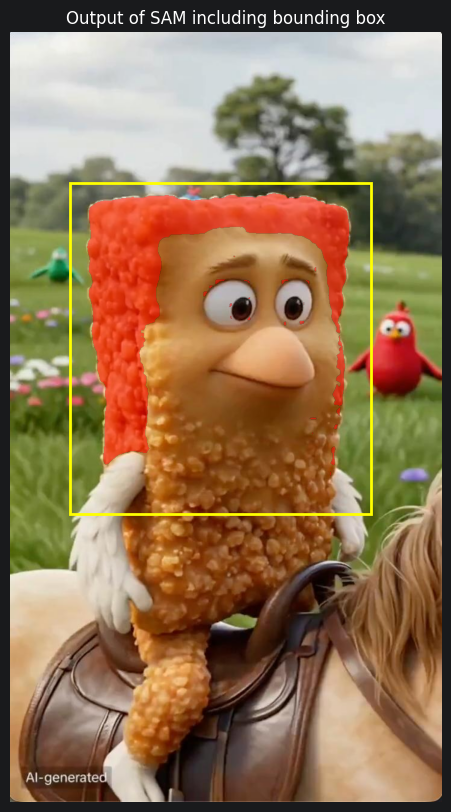

In [23]:
import matplotlib.pyplot as plt

mask = masks[0]

plt.figure(figsize=(10, 10))
plt.imshow(image)  # original image

# apply the mask
overlay = np.zeros((*mask.shape, 4), dtype=np.float32)
overlay[mask] = [1.0, 0.0, 0.0, 0.5]  # Color of the mask
plt.imshow(overlay)

# Show bounding box
plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                  edgecolor='yellow', facecolor='none', linewidth=2))

plt.title("Output of SAM including bounding box")
plt.axis('off')
plt.show()